# 08 — Cost-sensitive decisions, drift, and the deployable model

**Stage 12.** A high PR-AUC is not the goal; a better *decision* is. For every order the marketplace can expedite shipping or leave it alone.

| Symbol | Meaning | Default (assumption) |
|---|---|---|
| `E_i = handling + a · freight_i` | cost of expediting order *i*, paid whenever we act | handling 2 BRL, a = 0.5 |
| `L_i = b · (price_i + freight_i)` | damage if the order is late: refund, support, lost repeat business | b = 0.5 |
| `e` | share of late orders that expediting actually saves | 0.5 |

Acting on order *i* is worth `p_i · e · L_i − E_i` in expectation, so the rule is to **act when `p_i > t_i = E_i / (e · L_i)`**. This is the textbook `t* = C / (C + B)` with `C = E_i` and `B = e·L_i − E_i`. Because the threshold differs per order, an expensive parcel with cheap freight is worth protecting at a lower risk than a cheap one.

All three numbers are **assumptions**, so section 4 varies each by ±50%. The probabilities must be calibrated before they are compared with money (section 1).

In [1]:
import sys, time, warnings, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, psutil, joblib
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.frozen import FrozenEstimator
from sklearn.metrics import brier_score_loss, average_precision_score
from olist import config as C
from olist.decision import CostModel, policy_table, profit_curve, sensitivity, realised_saving, per_1000
from olist.modeling import load_task_a, task_a_sets, make_model
from olist.split import matured_by

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
proc = psutil.Process(); T0 = time.perf_counter()
rss = lambda: f"{proc.memory_info().rss/1e6:,.0f} MB"
def save(name): plt.savefig(C.FIGURES_DIR / f"08_{name}.png", bbox_inches="tight")
RESULTS = ROOT / "reports" / "results"; MODELS = ROOT / "models"

pop = load_task_a(); S = task_a_sets(pop)
TRAIN, VAL, TEST = S["train"], S["val"], S["test"]
F = json.load(open(MODELS / "task_a_features.json"))
best_params = json.load(open(RESULTS / "06_best_params.json"))
comp = pd.read_csv(RESULTS / "06_model_comparison.csv", index_col=0)
BEST = comp.loc[["logreg", "tree", "forest", "lgbm"], "val_pr_auc"].idxmax()
model = joblib.load(MODELS / f"task_a_{BEST}.joblib")
rule = joblib.load(MODELS / "task_a_business_rule.joblib")
cost = CostModel()
print(f"decision model: {BEST} (best validation PR-AUC) | cost assumptions: {cost.as_dict()}")
E, L = cost.expedite_cost(TEST), cost.late_damage(TEST)
print(f"test orders: median expedite cost {np.median(E):.1f} BRL, median late damage {np.median(L):.1f} BRL, "
      f"median break-even probability {np.median(cost.threshold(TEST)):.3f}")

decision model: logreg (best validation PR-AUC) | cost assumptions: {'a': 0.5, 'handling': 2.0, 'b': 0.5, 'e': 0.5}
test orders: median expedite cost 11.2 BRL, median late damage 54.8 BRL, median break-even probability 0.456


## 1. Calibrate before costing

The model is fitted on training data only. A sigmoid (Platt) and an isotonic calibrator are each fitted on the **validation** period and compared on test. The validation late rate (11.8%) is three times the test rate (3.8%), so any calibrator fitted on validation will over-predict on test. Section 5 measures how much that costs, and how much monthly recalibration recovers.

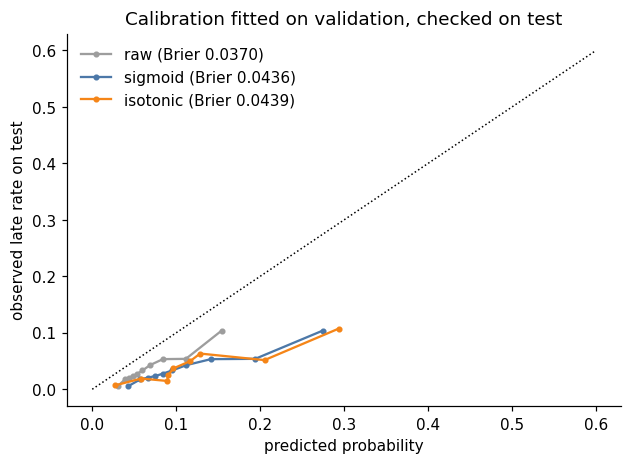

,test_brier,test_pr_auc,mean_predicted_%,actual_%
raw,0.0370,0.0827,6.9403,3.8112
sigmoid,0.0436,0.0827,11.4178,3.8112
isotonic,0.0439,0.0769,11.2447,3.8112


In [2]:
p_raw = {s: model.predict_proba(d[F])[:, 1] for s, d in [("val", VAL), ("test", TEST)]}
cal = {"raw": None}
for method in ["sigmoid", "isotonic"]:
    cal[method] = CalibratedClassifierCV(FrozenEstimator(model), method=method).fit(VAL[F], VAL.late_day.astype(int))
p_test = {"raw": p_raw["test"], **{m: c.predict_proba(TEST[F])[:, 1] for m, c in cal.items() if c is not None}}
cal_tab = pd.DataFrame({m: {"test_brier": brier_score_loss(TEST.late_day, p), "test_pr_auc": average_precision_score(TEST.late_day, p),
                            "mean_predicted_%": p.mean() * 100, "actual_%": TEST.late_day.mean() * 100} for m, p in p_test.items()}).T
fig, ax = plt.subplots(figsize=(6.5, 4.4))
for m, c in zip(p_test, ["#9D9D9D", "#4C78A8", "#F58518"]):
    fp, mp = calibration_curve(TEST.late_day, p_test[m], n_bins=10, strategy="quantile")
    ax.plot(mp, fp, marker="o", ms=3, color=c, label=f"{m} (Brier {cal_tab.loc[m, 'test_brier']:.4f})")
ax.plot([0, 0.6], [0, 0.6], color="k", ls=":", lw=1); ax.set_xlabel("predicted probability"); ax.set_ylabel("observed late rate on test")
ax.legend(frameon=False); ax.set_title("Calibration fitted on validation, checked on test")
save("calibration_methods"); plt.show()
cal_tab.round(4)

**Finding.** The raw logistic regression predicts a 6.9% average late rate on test, against an actual 3.8%. Calibrating on validation, a 11.8%-late period, pushes the level *up* to 11.2–11.4% and makes the Brier score worse (0.044 against 0.037 raw). Calibration only fixes probabilities for the period it was fitted on, so here it imports the validation regime into a calmer test period. Sigmoid is kept because it is slightly better than isotonic, but section 5 shows that **recalibrating on recent data** is what actually fixes the level.

## 2. Policies compared on test

Five policies are compared on the **realised** test outcomes, using the money model above:
* **do nothing:** the reference, saving 0 by definition;
* **act on every order:** expedite everything;
* **business rule:** expedite what the Stage 8 rule flags;
* **model, one threshold:** expedite when `p ≥ t`, with the single `t` that maximised savings on validation;
* **model, per-order cost rule:** expedite when `p_i > E_i / (e·L_i)`, using calibrated probabilities. No tuning is needed.

In [3]:
CAL = "sigmoid" if cal_tab.loc["sigmoid", "test_brier"] <= cal_tab.loc["isotonic", "test_brier"] else "isotonic"
p_val_cal = cal[CAL].predict_proba(VAL[F])[:, 1]
pc_val = profit_curve(VAL.late_day, p_val_cal, VAL, cost)
t_global = float(pc_val.loc[pc_val.saving_per_1000.idxmax(), "threshold"])
rule_mask = rule.predict(TEST[F]).astype(bool)
pol = policy_table(TEST.late_day, p_test[CAL], TEST, cost, global_threshold=t_global, rule_mask=rule_mask)
pol.to_csv(RESULTS / "08_policies_test.csv")
print(f"calibration used: {CAL} | single threshold chosen on validation: {t_global:.2f}")
pol.round(2)

calibration used: sigmoid | single threshold chosen on validation: 0.49


,acted_%,late_caught_%,saving_BRL,saving_per_1000_orders
policy,,,,
do nothing,0.00,0.00,0.00,0.00
act on every order,100.00,100.00,-236741.56,-12496.91
business rule,40.17,48.20,-107462.93,-5672.66
"model, one threshold (0.49)",0.00,0.00,0.00,0.00
"model, per-order cost rule",5.47,10.94,-5551.32,-293.04


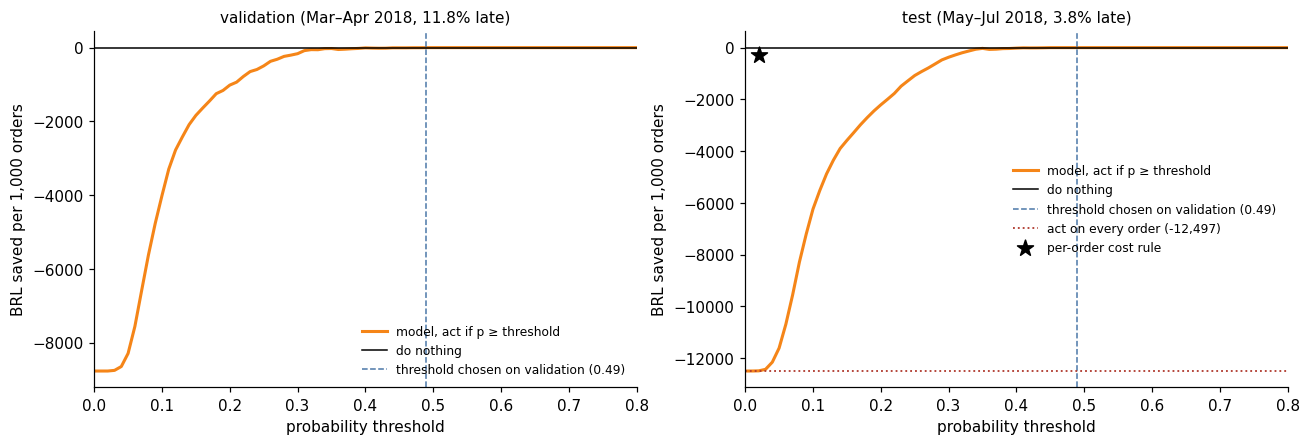

In [4]:
pc_test = profit_curve(TEST.late_day, p_test[CAL], TEST, cost)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, pc, nm in [(axes[0], pc_val, "validation (Mar–Apr 2018, 11.8% late)"), (axes[1], pc_test, "test (May–Jul 2018, 3.8% late)")]:
    ax.plot(pc.threshold, pc.saving_per_1000, color="#F58518", lw=2, label="model, act if p ≥ threshold")
    ax.axhline(0, color="k", lw=1, label="do nothing")
    ax.axvline(t_global, color="#4C78A8", ls="--", lw=1, label=f"threshold chosen on validation ({t_global:.2f})")
    ax.set_xlabel("probability threshold"); ax.set_ylabel("BRL saved per 1,000 orders"); ax.set_title(nm, fontsize=10)
    ax.set_xlim(0, 0.8)
yall = pol.loc["act on every order", "saving_per_1000_orders"]
axes[1].axhline(yall, color="#B03A2E", ls=":", lw=1.2, label=f"act on every order ({yall:,.0f})")
axes[1].scatter([0.02], [pol.loc["model, per-order cost rule", "saving_per_1000_orders"]], color="k", marker="*", s=120, zorder=5,
                label="per-order cost rule")
axes[1].legend(frameon=False, fontsize=8); axes[0].legend(frameon=False, fontsize=8)
save("profit_curves"); plt.show()

**Finding.** At the default assumptions, **no policy beats doing nothing in the test period**.
* Expediting every order loses 12,497 BRL per 1,000 orders.
* The business rule loses 5,673: it acts on 40% of orders to catch 48% of the late ones.
* The single threshold picked on validation (0.49) acts on **no** test orders, because the calibrated probabilities rarely reach it.
* The per-order cost rule acts on 5.5% of orders, catches 10.9% of late ones and loses **293 BRL per 1,000 orders**. It is 40× better than expediting everything, but still below zero.

The economics explain it. The median order costs about 11 BRL to expedite, while expediting a late order recovers on average only about 27 BRL (half of a 55 BRL damage). So the median break-even risk is **0.46**, and in a 3.8%-late month few orders get there. The same rule on validation (11.8% late) would have **saved 470 BRL per 1,000 orders**.

The rule does pick sensibly. Expedited orders are high-value (median 464 BRL against 81) and twice as likely to be late (7.6% against 3.6%).

## 3. Which orders get expedited?

In [5]:
act = p_test[CAL] > cost.threshold(TEST)
T = TEST.assign(p=p_test[CAL], act=act, threshold=cost.threshold(TEST), E=E, L=L)
who = T.groupby("act").agg(orders=("order_id", "size"), late_rate=("late_day", "mean"), median_p=("p", "median"),
                           median_threshold=("threshold", "median"), median_value=("total_price", "median"),
                           median_freight=("total_freight", "median"), median_distance=("distance_km_max", "median"))
who.index = who.index.map({False: "not expedited", True: "expedited"})
who.round(3)

,orders,late_rate,median_p,median_threshold,median_value,median_freight,median_distance
act,,,,,,,
not expedited,17908,0.036,0.086,0.477,80.995003,18.370001,399.613
expedited,1036,0.076,0.189,0.101,464.000000,22.520000,570.475


## 4. Sensitivity: does the recommendation survive different cost assumptions?

Each assumption is moved ±50% while the others stay at their defaults. The cost rule is re-derived for each scenario, since the threshold depends on the costs. The question is whether the model policy still beats both "do nothing" and "act on every order".

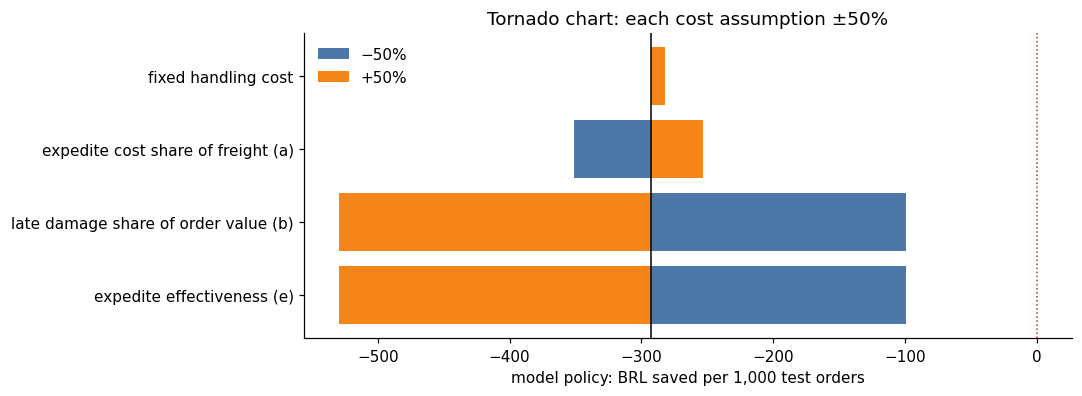

,parameter,change,value,model_saving_per_1000,act_all_saving_per_1000,acted_%,model_beats_both
0,a,-50%,0.25,-351.25,-6363.34,13.51,False
1,a,+50%,0.75,-253.30,-18630.49,3.06,False
2,handling,-50%,1.00,-288.19,-11496.91,6.54,False
3,handling,+50%,3.00,-281.97,-13496.91,4.58,False
4,b,-50%,0.25,-99.53,-13382.03,1.50,False
5,b,+50%,0.75,-529.28,-11611.80,10.96,False
6,e,-50%,0.25,-99.53,-13382.03,1.50,False
7,e,+50%,0.75,-529.28,-11611.80,10.96,False


In [6]:
sens = sensitivity(TEST.late_day, p_test[CAL], TEST, cost)
sens.to_csv(RESULTS / "08_sensitivity.csv", index=False)
base_saving = pol.loc["model, per-order cost rule", "saving_per_1000_orders"]
fig, ax = plt.subplots(figsize=(9, 3.6))
labels = {"a": "expedite cost share of freight (a)", "handling": "fixed handling cost", "b": "late damage share of order value (b)", "e": "expedite effectiveness (e)"}
for i, prm in enumerate(["e", "b", "a", "handling"]):
    lo = sens[(sens.parameter == prm) & (sens.change == "-50%")].model_saving_per_1000.iat[0]
    hi = sens[(sens.parameter == prm) & (sens.change == "+50%")].model_saving_per_1000.iat[0]
    ax.barh(i, lo - base_saving, left=base_saving, color="#4C78A8", label="−50%" if i == 0 else None)
    ax.barh(i, hi - base_saving, left=base_saving, color="#F58518", label="+50%" if i == 0 else None)
ax.axvline(base_saving, color="k", lw=1); ax.axvline(0, color="#B03A2E", ls=":", lw=1)
ax.set_yticks(range(4), [labels[p] for p in ["e", "b", "a", "handling"]]); ax.set_xlabel("model policy: BRL saved per 1,000 test orders")
ax.legend(frameon=False); ax.set_title("Tornado chart: each cost assumption ±50%")
save("tornado"); plt.show()
sens.round(2)

**Finding.** Across all eight one-at-a-time scenarios, the model policy loses between 100 and 529 BRL per 1,000 test orders. It always beats expediting everything by a wide margin (that policy loses 6,363–18,630), but never beats doing nothing in this low-lateness period. Raising `b` or `e` makes the model act more often (up to 11% of orders), which is the right direction but not yet enough.

### Break-even map: under which costs would the model pay off?

The tornado chart moves one assumption at a time. The map below moves the two that matter most together: the damage of a late order (`b`, as a share of order value) and the effectiveness of expediting (`e`). Each cell is the model policy's saving per 1,000 orders, with the cost rule re-derived for that cell. The black line marks break-even. The model itself is never changed; only the business assumptions vary.

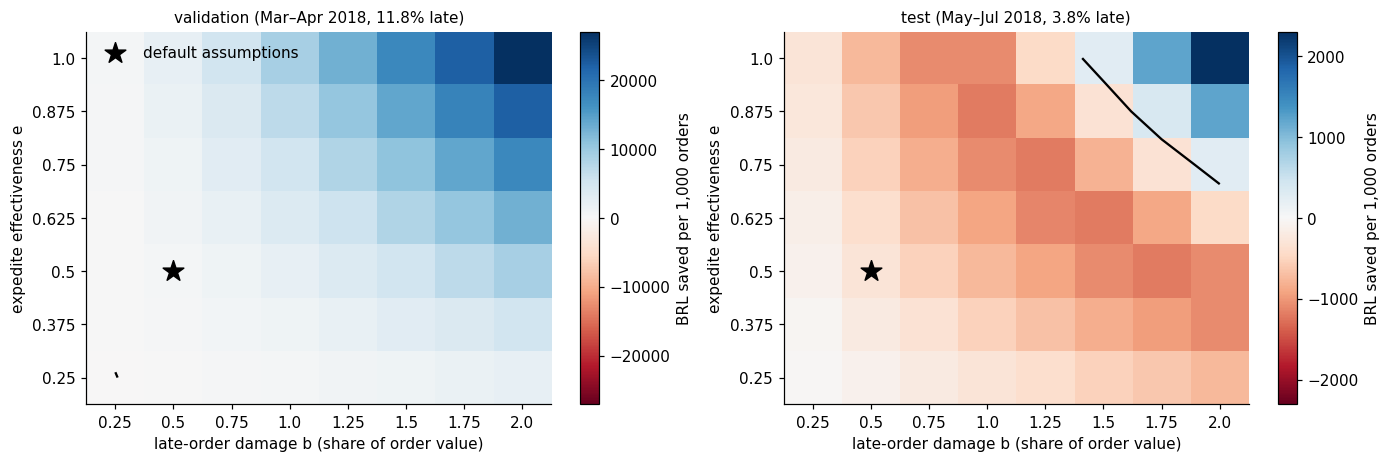

,0.25,0.50,0.75,1.00,1.25,1.50,1.75,2.00
0.250,-19.0,-100.0,-216.0,-293.0,-381.0,-529.0,-630.0,-748.0
0.375,-50.0,-216.0,-341.0,-529.0,-670.0,-836.0,-968.0,-1092.0
0.500,-100.0,-293.0,-529.0,-748.0,-917.0,-1092.0,-1193.0,-1091.0
0.625,-140.0,-381.0,-670.0,-917.0,-1128.0,-1197.0,-884.0,-450.0
0.750,-216.0,-529.0,-836.0,-1092.0,-1197.0,-805.0,-340.0,260.0
0.875,-259.0,-630.0,-968.0,-1193.0,-884.0,-340.0,375.0,1214.0
1.000,-293.0,-748.0,-1092.0,-1091.0,-450.0,260.0,1214.0,2305.0


In [7]:
grid_b, grid_e = np.round(np.linspace(0.25, 2.0, 8), 2), np.round(np.linspace(0.25, 1.0, 7), 3)
def saving_map(df, y, p):
    Z = np.zeros((len(grid_e), len(grid_b)))
    for i, ee in enumerate(grid_e):
        for j, bb in enumerate(grid_b):
            c = CostModel(a=cost.a, handling=cost.handling, b=bb, e=ee)
            Z[i, j] = per_1000(realised_saving(y, p > c.threshold(df), df, c), len(df))
    return pd.DataFrame(Z, index=grid_e, columns=grid_b)
maps = {"validation (Mar–Apr 2018, 11.8% late)": saving_map(VAL, VAL.late_day, p_val_cal),
        "test (May–Jul 2018, 3.8% late)": saving_map(TEST, TEST.late_day, p_test[CAL])}
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for ax, (nm, Z) in zip(axes, maps.items()):
    lim = np.abs(Z.to_numpy()).max()
    im = ax.imshow(Z.to_numpy(), origin="lower", cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
    ax.contour(Z.to_numpy(), levels=[0], colors="k", linewidths=1.5)
    ax.set_xticks(range(len(grid_b)), grid_b); ax.set_yticks(range(len(grid_e)), grid_e)
    ax.set_xlabel("late-order damage b (share of order value)"); ax.set_ylabel("expedite effectiveness e")
    ax.scatter([list(grid_b).index(0.5)], [list(grid_e).index(0.5)], marker="*", s=200, color="k", label="default assumptions")
    ax.set_title(nm, fontsize=10); fig.colorbar(im, ax=ax, label="BRL saved per 1,000 orders")
axes[0].legend(frameon=False, loc="upper left")
save("break_even_map"); plt.show()
maps["test (May–Jul 2018, 3.8% late)"].to_csv(RESULTS / "08_break_even_map_test.csv")
maps["test (May–Jul 2018, 3.8% late)"].round(0)

**Finding.** The two periods tell opposite stories:
* **Validation (11.8% late):** the model pays off almost everywhere. It saves +470 BRL per 1,000 orders at the defaults, +2,305 if a late order costs its full value (b = 1), and up to +27,074 in the most favourable corner.
* **Test (3.8% late):** only the top-right corner breaks even, where expediting works at least 75% of the time **and** a late order costs about 1.75–2× its value (+260 to +2,305).

**Recommendation for the business.**
1. Use the model to expedite only when lateness is running high, and only for orders where a late delivery is genuinely expensive (high value, or a valuable repeat customer).
2. For **near-zero-cost actions**, such as showing a more honest ETA or sending a proactive message, the cost `E` falls toward 0, the break-even probability falls with it, and the model is useful in every period.
3. Measure `e` with an A/B test before spending money on expediting.

## 5. Drift: train once, or keep the model fresh?

Three strategies are scored month by month on the test period:
1. **static:** the model trained up to Feb 2018 and calibrated on Mar–Apr, used unchanged (as in sections 1–4);
2. **monthly recalibration:** the same fitted model, recalibrated (sigmoid) at the start of each test month on the matured orders of the previous 45 days;
3. **monthly retraining:** the tuned configuration refitted at the start of each test month on every order whose promised day has already passed, then recalibrated the same way.

"Matured" means the order's promised day had passed by the month start, so no strategy uses a label that was not yet known.

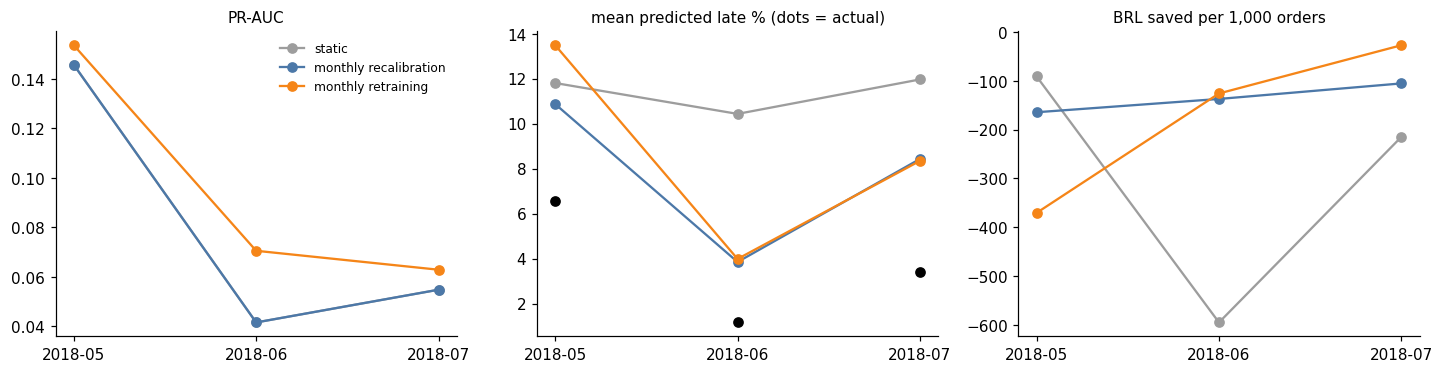

,month,strategy,train_rows,recal_rows,late_%,mean_pred_%,pr_auc,brier,acted_%,saving_per_1000
0,2018-05,static,50356,4763,6.564,11.808,0.146,0.062,7.601,-91.089
1,2018-05,monthly recalibration,50356,4763,6.564,10.872,0.146,0.064,7.453,-164.363
2,2018-05,monthly retraining,65490,4763,6.564,13.488,0.154,0.070,10.342,-370.395
3,2018-06,static,50356,5731,1.165,10.436,0.042,0.023,4.052,-594.790
4,2018-06,monthly recalibration,50356,5731,1.165,3.852,0.042,0.012,0.705,-137.152
5,2018-06,monthly retraining,73330,5731,1.165,3.988,0.071,0.012,0.755,-125.915
6,2018-07,static,50356,2571,3.410,11.967,0.055,0.044,4.525,-214.908
7,2018-07,monthly recalibration,50356,2571,3.410,8.432,0.055,0.040,3.296,-105.341
8,2018-07,monthly retraining,77906,2571,3.410,8.347,0.063,0.039,2.837,-27.170


In [8]:
params = dict(best_params[BEST])
if BEST == "lgbm":
    params["n_jobs"] = 8
rows, drift_preds = [], {k: np.zeros(len(TEST)) for k in ["static", "monthly recalibration", "monthly retraining"]}
for month in ["2018-05", "2018-06", "2018-07"]:
    start = pd.Timestamp(month); end = start + pd.offsets.MonthBegin(1)
    idx = np.flatnonzero(((TEST.order_purchase_timestamp >= start) & (TEST.order_purchase_timestamp < end)).to_numpy())
    known = pop[(pop.order_purchase_timestamp < start) & matured_by(pop, start)]
    last = known[known.order_purchase_timestamp >= start - pd.Timedelta(days=45)]       # most recent matured orders
    recal = CalibratedClassifierCV(FrozenEstimator(model), method="sigmoid").fit(last[F], last.late_day.astype(int))
    fresh = make_model(BEST, F, **params).fit(known[F], known.late_day)
    fresh_cal = CalibratedClassifierCV(FrozenEstimator(fresh), method="sigmoid").fit(last[F], last.late_day.astype(int))
    Xm = TEST.iloc[idx]
    for name, est in [("static", cal[CAL]), ("monthly recalibration", recal), ("monthly retraining", fresh_cal)]:
        p = est.predict_proba(Xm[F])[:, 1]; drift_preds[name][idx] = p
        actm = p > cost.threshold(Xm)
        rows.append({"month": month, "strategy": name, "train_rows": len(known) if name == "monthly retraining" else len(TRAIN),
                     "recal_rows": len(last), "late_%": Xm.late_day.mean() * 100, "mean_pred_%": p.mean() * 100,
                     "pr_auc": average_precision_score(Xm.late_day, p), "brier": brier_score_loss(Xm.late_day, p),
                     "acted_%": actm.mean() * 100, "saving_per_1000": per_1000(realised_saving(Xm.late_day, actm, Xm, cost), len(Xm))})
drift = pd.DataFrame(rows)
drift.to_csv(RESULTS / "08_drift.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, metric, title in zip(axes, ["pr_auc", "mean_pred_%", "saving_per_1000"], ["PR-AUC", "mean predicted late % (dots = actual)", "BRL saved per 1,000 orders"]):
    for (name, g), c in zip(drift.groupby("strategy", sort=False), ["#9D9D9D", "#4C78A8", "#F58518"]):
        ax.plot(g.month, g[metric], marker="o", color=c, label=name)
    if metric == "mean_pred_%":
        ax.scatter(drift.month.unique(), drift.groupby("month", sort=False)["late_%"].first(), color="k", zorder=5, label="actual")
    ax.set_title(title, fontsize=10)
axes[0].legend(frameon=False, fontsize=8)
save("drift"); plt.show()
drift.round(3)

**Finding.** The static model over-predicts in every test month: it predicts 10.4–12.0% while the actual rate is 1.2–6.6%.
* **Monthly recalibration** pulls the level down: 3.9% predicted against 1.2% actual in June, and 8.4% against 3.4% in July. It cuts the June loss from −595 to −137 and the July loss from −215 to −105, at a small cost in May.
* **Monthly retraining** also improves the *ranking*: PR-AUC rises from 0.146 to 0.154 in May, 0.042 to 0.071 in June and 0.055 to 0.063 in July. It gives the smallest July loss (−27), with the gap closing month by month.
* Over the three months, mean PR-AUC is 0.081 for the static model (the same with recalibration only) and **0.096 with retraining**.

**Decision.** Run the model fresh: retrain monthly on every matured label and recalibrate on the most recent orders. The deployable artefact below follows that recipe.

## 6. The deployable artefact

After the test evaluation, the artefact used by `predict.py` is rebuilt the way the drift experiment recommends: fresh and recently calibrated. At the data snapshot (`T_OBS` = 3 Sep 2018) every population label is known, so:
* the tuned configuration is refitted on **every population order purchased before July 2018**;
* it is calibrated (sigmoid) on **July 2018**, the most recent month, held out from the fit;
* the cost assumptions and feature list are stored next to it, so `predict.py` applies exactly the rule evaluated above.

In [9]:
cut = pd.Timestamp("2018-07-01")
fit_rows, cal_rows = pop[pop.order_purchase_timestamp < cut], pop[pop.order_purchase_timestamp >= cut]
final = make_model(BEST, F, **params).fit(fit_rows[F], fit_rows.late_day)
final_cal = CalibratedClassifierCV(FrozenEstimator(final), method="sigmoid").fit(cal_rows[F], cal_rows.late_day.astype(int))
joblib.dump(final_cal, MODELS / "task_a_deploy.joblib")
meta = {"model": BEST, "params": best_params[BEST], "calibration": "sigmoid, fitted on July 2018 (held out)",
        "trained_on": f"{len(fit_rows):,} orders purchased {fit_rows.order_purchase_timestamp.min().date()} -> {fit_rows.order_purchase_timestamp.max().date()}",
        "calibrated_on": f"{len(cal_rows):,} orders purchased in July 2018 ({cal_rows.late_day.mean():.2%} late)",
        "features": F, "cost_model": cost.as_dict(),
        "decision_rule": "expedite when p_late > (handling + a*freight) / (e * b * (price + freight))"}
json.dump(meta, open(MODELS / "task_a_deploy_meta.json", "w"), indent=2, default=str)
print(json.dumps({k: v for k, v in meta.items() if k not in ("features", "params")}, indent=2))

{
  "model": "logreg",
  "calibration": "sigmoid, fitted on July 2018 (held out)",
  "trained_on": "83,696 orders purchased 2017-01-05 -> 2018-06-30",
  "calibrated_on": "6,099 orders purchased in July 2018 (3.41% late)",
  "cost_model": {
    "a": 0.5,
    "handling": 2.0,
    "b": 0.5,
    "e": 0.5
  },
  "decision_rule": "expedite when p_late > (handling + a*freight) / (e * b * (price + freight))"
}


In [10]:
print(f"notebook runtime {time.perf_counter()-T0:.1f}s | final RSS {rss()}")

notebook runtime 6.9s | final RSS 645 MB
